## Análisis de modelos

## SVM

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve
from itertools import product

from sklearn.svm import SVC, LinearSVC
from sklearn.pipeline import Pipeline
import time
import os
import joblib
from sklearn.calibration import CalibratedClassifierCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

In [2]:
df = pd.read_csv("../data/raw/billboard_processed.csv")

df.head()

,performer,spotify_genre,spotify_track_duration_ms,spotify_track_explicit,danceability,key,loudness,mode,speechiness,instrumentalness,tempo,time_signature,acoustic_mood_cluster,top30
0,The Weeknd,"['canadian contemporary r&b', 'canadian pop', ...",201573.0,False,0.513,1.0,-4.075,1.0,0.0629,0.000209,171.017,4.0,intense_aggressive_drive,1
1,LMFAO Featuring Lauren Bennett & GoonRock,"['dance pop', 'pop', 'pop rap']",262173.0,False,0.750,5.0,-4.210,0.0,0.1420,0.000000,129.993,4.0,intense_aggressive_drive,1
2,Adele,"['british soul', 'pop', 'uk pop']",228293.0,False,0.729,8.0,-5.119,1.0,0.0294,0.000000,104.945,4.0,balanced_acoustic_pop,1
3,Post Malone,"['dfw rap', 'melodic rap', 'rap']",215280.0,False,0.695,0.0,-3.497,1.0,0.0395,0.002440,120.042,4.0,balanced_acoustic_pop,1
4,Los Del Rio,"['deep norteno', 'duranguense', 'norteno', 'no...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,balanced_acoustic_pop,1


## Analizar variable "top30":

top30
0    18112
1    12659
Name: count, dtype: int64

Porcentajes:
top30
0    58.860616
1    41.139384
Name: proportion, dtype: float64


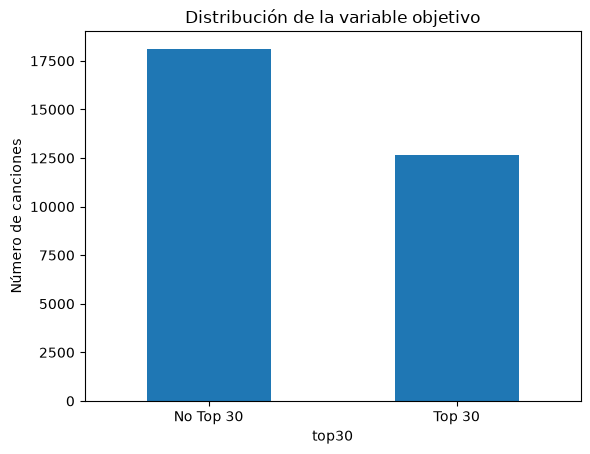

In [3]:
print(df["top30"].value_counts())
print("\nPorcentajes:")
print(df["top30"].value_counts(normalize=True) * 100)

df["top30"].value_counts().sort_index().plot(
    kind="bar",
    rot=0
)

plt.xticks([0, 1], ["No Top 30", "Top 30"])
plt.ylabel("Número de canciones")
plt.title("Distribución de la variable objetivo")
plt.show()

## Separamos train y test:

In [4]:
X = df.drop(columns=["top30"])
y = df["top30"]

X_resto, X_test, y_resto, y_test = train_test_split(X, y, test_size=0.10, random_state=42, stratify=y)

X_train, X_val, y_train, y_val = train_test_split(X_resto, y_resto, test_size=0.10, random_state=42, stratify=y_resto)


print(X_train.shape,X_val.shape, X_test.shape)
print('En train:', round(y_train.mean() * 100, 2), "%", 'En validación: ',round(y_val.mean()*100,2),"%" , '  en test:', round(y_test.mean() * 100, 2), "%")

(24923, 13) (2770, 13) (3078, 13)
En train: 41.14 % En validación:  41.16 %   en test: 41.13 %


In [5]:
print("Columnas de X:")
print(X_train.columns.tolist())

print("\nDimensiones:")
print(X_train.shape)

print("\nColumnas con nulos:")
print(X_train.isna().sum()[X_train.isna().sum() > 0])

Columnas de X:
['performer', 'spotify_genre', 'spotify_track_duration_ms', 'spotify_track_explicit', 'danceability', 'key', 'loudness', 'mode', 'speechiness', 'instrumentalness', 'tempo', 'time_signature', 'acoustic_mood_cluster']

Dimensiones:
(24923, 13)

Columnas con nulos:
spotify_track_duration_ms    2976
spotify_track_explicit       2976
danceability                 3025
key                          3025
loudness                     3025
mode                         3025
speechiness                  3025
instrumentalness             3025
tempo                        3025
time_signature               3025
dtype: int64


## Aplicamos el análisis en X_train

In [6]:
variables_media = ["danceability", "speechiness", "instrumentalness", "tempo"]
variables_mediana = ["loudness"]
variables_moda = ["key", "mode", "time_signature"]

globales_mediana = ["spotify_track_duration_ms"]
globales_moda = ["spotify_track_explicit"]

cluster_col = "acoustic_mood_cluster"
columnas_cluster = variables_media + variables_mediana + variables_moda
columnas_globales = globales_mediana + globales_moda
columnas = columnas_cluster + columnas_globales

print("Nulos TRAIN antes:")
print(X_train[columnas].isna().sum())

stats_cluster = {}   # {columna: Serie indexada por cluster}
stats_global = {}    # {columna: valor global}

for col in variables_media:
    stats_cluster[col] = X_train.groupby(cluster_col)[col].mean()
    stats_global[col] = X_train[col].mean()

    valor_cluster = X_train[cluster_col].map(stats_cluster[col])
    X_train[col] = X_train[col].fillna(valor_cluster)
    X_train[col] = X_train[col].fillna(stats_global[col])

for col in variables_mediana:
    stats_cluster[col] = X_train.groupby(cluster_col)[col].median()
    stats_global[col] = X_train[col].median()

    valor_cluster = X_train[cluster_col].map(stats_cluster[col])
    X_train[col] = X_train[col].fillna(valor_cluster)
    X_train[col] = X_train[col].fillna(stats_global[col])

for col in variables_moda:
    stats_cluster[col] = X_train.groupby(cluster_col)[col].agg(
        lambda x: x.mode().iloc[0] if not x.mode().empty else float("nan")
    )
    moda_global = X_train[col].mode()
    stats_global[col] = moda_global.iloc[0] if not moda_global.empty else float("nan")

    valor_cluster = X_train[cluster_col].map(stats_cluster[col])
    X_train[col] = X_train[col].fillna(valor_cluster)
    X_train[col] = X_train[col].fillna(stats_global[col])

for col in globales_mediana:
    stats_global[col] = X_train[col].median()
    X_train[col] = X_train[col].fillna(stats_global[col])

for col in globales_moda:
    moda_global = X_train[col].mode()
    stats_global[col] = moda_global.iloc[0] if not moda_global.empty else float("nan")
    X_train[col] = X_train[col].fillna(stats_global[col])

print("\nNulos TRAIN después:")
print(X_train[columnas].isna().sum())

print("\nEstadísticas globales guardadas (train):")
print(stats_global)

Nulos TRAIN antes:
danceability                 3025
speechiness                  3025
instrumentalness             3025
tempo                        3025
loudness                     3025
key                          3025
mode                         3025
time_signature               3025
spotify_track_duration_ms    2976
spotify_track_explicit       2976
dtype: int64

Nulos TRAIN después:
danceability                 0
speechiness                  0
instrumentalness             0
tempo                        0
loudness                     0
key                          0
mode                         0
time_signature               0
spotify_track_duration_ms    0
spotify_track_explicit       0
dtype: int64

Estadísticas globales guardadas (train):
{'danceability': np.float64(0.6020063932779248), 'speechiness': np.float64(0.08950473102566445), 'instrumentalness': np.float64(0.032657926696501964), 'tempo': np.float64(121.06935149328706), 'loudness': -8.13, 'key': np.float64(0.0), 'mode'

C:\Users\Alicia.martinez\AppData\Local\Temp\ipykernel_20288\3074567703.py:53: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_train[col] = X_train[col].fillna(stats_global[col])


## Rellenamos nulos en X_val 

In [7]:
print("Nulos VAL antes:")
print(X_val[columnas].isna().sum())

for col in columnas_cluster:
    valor_cluster = X_val[cluster_col].map(stats_cluster[col])
    X_val[col] = X_val[col].fillna(valor_cluster)
    X_val[col] = X_val[col].fillna(stats_global[col])

for col in columnas_globales:
    X_val[col] = X_val[col].fillna(stats_global[col])

print("\nNulos VAL después:")
print(X_val[columnas].isna().sum())

Nulos VAL antes:
danceability                 319
speechiness                  319
instrumentalness             319
tempo                        319
loudness                     319
key                          319
mode                         319
time_signature               319
spotify_track_duration_ms    315
spotify_track_explicit       315
dtype: int64

Nulos VAL después:
danceability                 0
speechiness                  0
instrumentalness             0
tempo                        0
loudness                     0
key                          0
mode                         0
time_signature               0
spotify_track_duration_ms    0
spotify_track_explicit       0
dtype: int64


C:\Users\Alicia.martinez\AppData\Local\Temp\ipykernel_20288\707013219.py:10: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_val[col] = X_val[col].fillna(stats_global[col])


## Rellenamos nulos en X_test

In [8]:
print("Nulos TEST antes:")
print(X_test[columnas].isna().sum())

for col in columnas_cluster:
    valor_cluster = X_test[cluster_col].map(stats_cluster[col])
    X_test[col] = X_test[col].fillna(valor_cluster)
    X_test[col] = X_test[col].fillna(stats_global[col])

for col in columnas_globales:
    X_test[col] = X_test[col].fillna(stats_global[col])

print("\nNulos TEST después:")
print(X_test[columnas].isna().sum())

Nulos TEST antes:
danceability                 365
speechiness                  365
instrumentalness             365
tempo                        365
loudness                     365
key                          365
mode                         365
time_signature               365
spotify_track_duration_ms    359
spotify_track_explicit       359
dtype: int64

Nulos TEST después:
danceability                 0
speechiness                  0
instrumentalness             0
tempo                        0
loudness                     0
key                          0
mode                         0
time_signature               0
spotify_track_duration_ms    0
spotify_track_explicit       0
dtype: int64


C:\Users\Alicia.martinez\AppData\Local\Temp\ipykernel_20288\3823342436.py:10: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_test[col] = X_test[col].fillna(stats_global[col])


In [9]:

print("Train:", X_train.isna().sum().sum())
print("Validation:", X_val.isna().sum().sum())

Train: 0
Validation: 0


## Realizamos OneHotEncoder
- A las variables de tipo texto las convertimos en números ya que la regresión logística se hace con números.
- Tras realizar la ejeccución nos dimos cuenta que siguiendo este hilo daba sobreajuste.

In [10]:
texto = ["performer", "spotify_genre", "acoustic_mood_cluster", "spotify_track_explicit"]
encoder = OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False)
encoder.fit(X_train[texto])  
nombres = encoder.get_feature_names_out(texto)
print(nombres)

cat_train = pd.DataFrame(encoder.transform(X_train[texto]), columns=nombres, index=X_train.index)
cat_val = pd.DataFrame(encoder.transform(X_val[texto]), columns=nombres, index=X_val.index)
cat_test = pd.DataFrame(encoder.transform(X_test[texto]), columns=nombres, index=X_test.index)

X_train = pd.concat([X_train.drop(columns=texto), cat_train], axis=1)
X_val =  pd.concat([X_val.drop(columns=texto), cat_val], axis=1)
X_test = pd.concat([X_test.drop(columns=texto), cat_test], axis=1)
print('Columnas del modelo:', X_train.shape[1])
X_train.head()

print("Nulos después del OneHotEncoder:")
print("Train:", X_train.isna().sum().sum())
print("Validation:", X_val.isna().sum().sum())
print("Test:", X_test.isna().sum().sum())


['performer_"Little" Jimmy Dickens' 'performer_"Pookie" Hudson'
 'performer_"Weird Al" Yankovic' ...
 'acoustic_mood_cluster_intense_aggressive_drive'
 'acoustic_mood_cluster_moody_melancholic' 'spotify_track_explicit_True']


c:\Users\Alicia.martinez\AppData\Local\anaconda3\envs\clase1\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\Alicia.martinez\AppData\Local\anaconda3\envs\clase1\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Columnas del modelo: 11001
Nulos después del OneHotEncoder:
Train: 0
Validation: 0
Test: 0


## Baseline: predecir siempre la moda

In [11]:
moda = y_train.mode()[0]
pred_moda = np.full(len(y_train), moda)
print("Clase más frecuente:", moda)
print("F1 prediciendo siempre la moda:", f1_score(y_train, pred_moda, zero_division=0))

Clase más frecuente: 0
F1 prediciendo siempre la moda: 0.0


## SVM sin escalar y escalada

In [12]:
svm_sin = LinearSVC(max_iter=3000, random_state=42)

svm_sin.fit(X_train, y_train)

pred_sin = svm_sin.predict(X_val)

f1_sin = f1_score(y_val, pred_sin)

print("F1 en validación sin escalar:", round(f1_sin, 3))

F1 en validación sin escalar: 0.0


In [13]:
svm_esc = Pipeline([
    ("escalar", StandardScaler()),
    ("svm", LinearSVC(max_iter=3000, random_state=42))
])

svm_esc.fit(X_train, y_train)

pred_esc = svm_esc.predict(X_val)

f1_esc = f1_score(y_val, pred_esc)

print("F1 en validación escalada:", round(f1_esc, 3))

F1 en validación escalada: 0.565


In [14]:
print("SVM sin escalar:", round(f1_sin, 3))
print("SVM escalado:", round(f1_esc, 3))

SVM sin escalar: 0.0
SVM escalado: 0.565


## Búsqueda del mejor c en un SVM lineal

In [15]:
rejilla_lineal = [0.001, 0.01, 0.1, 1]

filas = []
for C in rejilla_lineal:
    t = time.time()
    modelo = Pipeline([("escalar", StandardScaler()),
                       ("svm", LinearSVC(C=C, max_iter=5000,random_state=42, dual="auto"))])
    modelo.fit(X_train, y_train)
    filas.append({"C": C, "gamma": None,
                  "train_f1": f1_score(y_train, modelo.predict(X_train)),
                  "val_f1": f1_score(y_val, modelo.predict(X_val))})
    print(f"linear C={C} -> {time.time() - t:.0f} s")

res = pd.DataFrame(filas)
print(res.sort_values("val_f1", ascending=False))

mejor = res.sort_values("val_f1", ascending=False).iloc[0]
print("Mejor valor de C:", mejor["C"])
print("F1 en validación:", round(mejor["val_f1"], 3))

linear C=0.001 -> 791 s
linear C=0.01 -> 2307 s
linear C=0.1 -> 2317 s
linear C=1 -> 936 s
       C gamma  train_f1    val_f1
0  0.001  None  0.733520  0.565949
3  1.000  None  0.734143  0.564584
1  0.010  None  0.733862  0.564319
2  0.100  None  0.734153  0.564319
Mejor valor de C: 0.001
F1 en validación: 0.566


In [ ]:
svm_final = CalibratedClassifierCV(
    estimator=Pipeline([
        ("escalar", StandardScaler()),
        ("svm", LinearSVC(
            C=mejor["C"],
            max_iter=5000,
            random_state=42,
            dual="auto"
        ))
    ]),
    method="sigmoid",
    cv=5
)

svm_final.fit(X_train, y_train)

In [ ]:
probs_test = svm_final.predict_proba(X_test)[:, 1]
predicciones_test = (probs_test >= 0.5).astype(int)

print("MÉTRICAS EN TRAIN")
print("Accuracy:", accuracy_score(y_train, predicciones_test))
print("Precision:", precision_score(y_train, predicciones_test))
print("Recall:", recall_score(y_train, predicciones_test))
print("F1-score:", f1_score(y_train, predicciones_test))
print("ROC-AUC:", roc_auc_score(y_train, probs_test))

AttributeError: This 'Pipeline' has no attribute 'predict_proba'

## SVM lineal: F1 según C

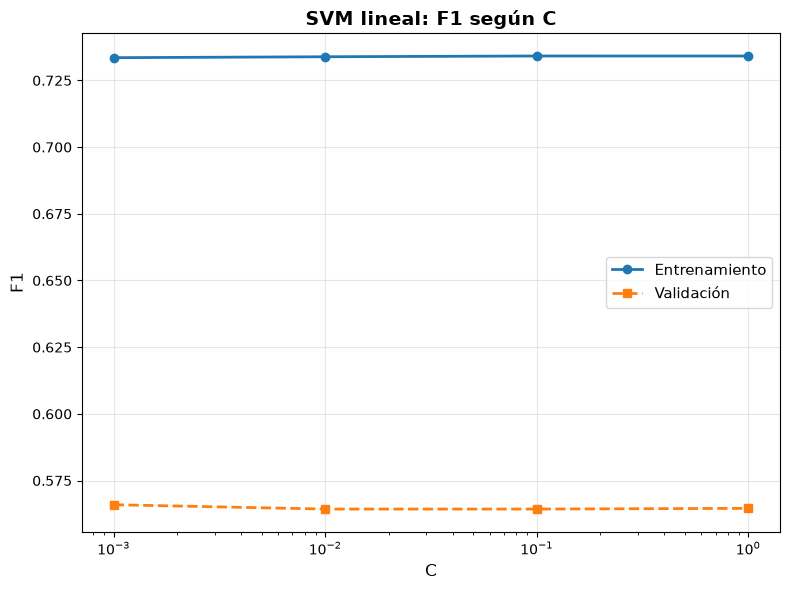

In [ ]:
plt.figure(figsize=(8, 6))
plt.plot(res["C"], res["train_f1"], "o-", label="Entrenamiento", linewidth=2)
plt.plot(res["C"], res["val_f1"], "s--", label="Validación", linewidth=2)

plt.xscale("log")
plt.title("SVM lineal: F1 según C", fontsize=14, fontweight="bold")
plt.xlabel("C", fontsize=12)
plt.ylabel("F1", fontsize=12)
plt.legend(fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Probamos el modelo con test

In [ ]:
probs_test = svm_final.predict_proba(X_test)[:, 1]

predicciones_test = (probs_test >= 0.5).astype(int)

print("MÉTRICAS EN TEST")
print("Accuracy:", accuracy_score(y_test, predicciones_test))
print("Precision:", precision_score(y_test, predicciones_test))
print("Recall:", recall_score(y_test, predicciones_test))
print("F1-score:", f1_score(y_test, predicciones_test))
print("ROC-AUC:", roc_auc_score(y_test, probs_test))

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

matriz = confusion_matrix(y_test, predicciones_test)

ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["No entra", "Entra"]
).plot(cmap="Blues")

plt.title("Matriz de confusión - Random Forest TEST")
plt.show()

## Guardar modelo

In [ ]:
joblib.dump(svm_final, "../model/modelo_SVM.pkl")

['../model/modelo_SVM.pkl']

## Evaluación del modelo

En el modelo SVM observamos que el escalado de las variables resulta fundamental para obtener un rendimiento adecuado, ya que el modelo sin escalado obtiene un F1 de validación de 0, mientras que al aplicar StandardScaler alcanza un F1 de 0,565.

Posteriormente, realizamos una búsqueda del hiperparámetro C para optimizar el SVM lineal. El mejor resultado se obtiene con C=0,001, alcanzando un F1 de validación de 0,566. No obstante, las diferencias entre los distintos valores probados son reducidas, lo que indica cierta estabilidad del modelo frente a este hiperparámetro.

Aunque existe una diferencia entre el rendimiento en entrenamiento y validación, el SVM presenta resultados prometedores y se posiciona como un candidato competitivo para la predicción del éxito musical. Su selección definitiva dependerá también de su capacidad para minimizar los falsos positivos, aspecto especialmente importante para las decisiones de inversión de la discográfica.